### Corrective RAG
Corrective RAV(RAG)is an advanced technique with in Retrieval Augmented Generation (RAG) that focus on improving the accuracy and relevance of generated response by incorporating mechanisms for self-reflection and self-grading of retrieved documents. It does this by evaluating the quality of retrieved documents. It does this  by evaluating the quality of retrieved documents and applying corrective actions when necessary, such as refining or replacing incorrect retrievals.

CRAG's core Components :
1. Retrieval Evaluator :  This component assesses the quality and relevance of retrieved documents.
2. Generative Model : This model generates the intiial responses based on the retrieved informtion.
3. Refinement and Correction : CRAG employs strategies like knowledge refinement or web search to address issues identified by the retrieval evaluator.

Benefits of CRAG

1. Improved Accuracy : By evaluating and correcting retrieved information, CRAG helps ensure the accuracy of generated responses.
2. Enahanced Relevance : CRAG can identify and filter out irrelevant information, making the generated response more releveant.
3. Increased Robustness : CRAG can handle cases where the initial retrieval process is not perfect, leading to a more robust RAG system

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")


In [3]:
import truststore   
truststore.inject_into_ssl()

In [4]:

#build Index
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings

### from langchain_cohere import CohereEmbeddings

#Set Embeddings
embd = OpenAIEmbeddings()

urls = ["https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/",
    "https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/",
]

#Load
docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(chunk_size=500, chunk_overlap=0)
docs_splits = text_splitter.split_documents(docs_list)

#Add to Vectorsstore - Build Index
vectorstore = FAISS.from_documents(
    documents=docs_splits,
    embedding=OpenAIEmbeddings()
)

retriever = vectorstore.as_retriever()


C:\Users\nmadan\AppData\Local\Temp\ipykernel_49748\1950418910.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [6]:
### Retrieval Grader

from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

from pydantic import BaseModel, Field

#  Data model
class GradedDocuments(BaseModel):
    """Binary score for relevance check on retrieved documents."""
    
    binary_score : str = Field(
        description="Documents are relevant to the question, 'yes'or 'no'"
    )

#LLM with function call
llm = ChatOpenAI(model="gpt-4", temperature=0)
structured_llm_grader = llm.with_structured_output(GradedDocuments)

#Prompt
system = """ You are a grader assessing relevance of a retrieved document to a user question. \n
             if the document  contains keyword(s) or semantic meaning releated to the question, grade it as relevant. \n
             Give a binary score 'yes' or 'no' score to indicate whether the document is relevant to the question. """

grade_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        ("human", "Retrieved document :\n\n {document} \n\n User question : {question}"),
    ]
)

retrieval_grader = grade_prompt | structured_llm_grader
question = "agent memory"
docs = retriever.invoke(question)
doc_txt = docs[1].page_content
print(retrieval_grader.invoke({"question" : question, "document" : doc_txt}))



c:\ML\.venv\Lib\site-packages\langchain_openai\chat_models\base.py:2763: UserWarning: Cannot use method='json_schema' with model gpt-4 since it doesn't support OpenAI's Structured Output API. You can see supported models here: https://platform.openai.com/docs/guides/structured-outputs#supported-models. To fix this warning, set `method='function_calling'. Overriding to method='function_calling'.
  warnings.warn(


binary_score='yes'


In [7]:
### Generate
from langchain_classic import hub
from langsmith import Client
#from langchain import hub
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

client = Client()
#Prompt
prompt = client.pull_prompt("rlm/rag-prompt", 
                dangerously_pull_public_prompt=True,)
        

llm = ChatOpenAI(model="gpt-4", temperature=0)

#Post-processing
def format_docs(docs):
    return "\n\n".join([doc.page_content for doc in docs])

# Chain
rag_chain = prompt | llm | StrOutputParser()

#Run
generation = rag_chain.invoke({"context" : format_docs(docs), "question" : question })
print(generation)

Agent memory refers to the capability of an agent to retain and recall information. It is divided into short-term memory, which utilizes in-context learning, and long-term memory, which often leverages an external vector store and fast retrieval. The memory stream is a long-term memory module that records a comprehensive list of agents’ experiences in natural language, and the retrieval model surfaces the context to inform the agent’s behavior according to relevance, recency, and importance.


In [8]:
### Question rewiter

#LLM
llm = ChatOpenAI(model="gpt-4o", temperature=0)
system = """ You a question re-writer that converts an input question to a better version that is optimized \n
            for web search. Look at the input and try to reason about the underlying semantic intent /meaning. """

re_write_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        ("human", "Here is the initial question \n\n {question} \n Formulate an improved question."),
    ]
)

question_rewriter = re_write_prompt | llm | StrOutputParser()
question_rewriter.invoke({"question": question})


'What is the role and function of memory in artificial intelligence agents?'

In [15]:
from langchain_community.tools.tavily_search import TavilySearchResults

web_search_tool = TavilySearchResults(k=3)

C:\Users\nmadan\AppData\Local\Temp\ipykernel_4448\1505316070.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  web_search_tool = TavilySearchResults(k=3)


In [10]:
from typing import List
from typing_extensions import TypedDict
from langchain_core.documents import Document

class GraphState(TypedDict):
    """
    Represents the state of a graph.

    Attributes:
        question: question
        generation: LLM generation
        web_search: whether to add search
        documents: list of retrieved documents
    """
    question: str
    generation: str
    web_search: str
    documents: List[Document]

In [18]:
def retrieve(state) :
    """
    Retrieves documents

    Args:
        state(dict): The current state of the graph.

    Returns:
        state (dict):New key added to state, documents, that contains retrieved documents.
    """
    print("--RETRIEVE---")
    question = state["question"]

    # Retrieval
    documents = retriever.invoke(question)
    return {"documents" : documents, "question" : question}


def generate(state):
    """
    Generates answer

    Args:
        state(dict): The current state of the graph.

    Returns:
        state (dict): New key added to state, generation, that contains LLM generation.
    """
    print("--GENERATE---")
    question = state["question"]
    #documents = state["documents"]
    documents = state.get("documents", [])

    print("Documents received:", len(documents))
    # Generation
    generation = rag_chain.invoke(
        {"question": question, "context": format_docs(documents)}
    )
    return {"generation": generation, "question": question, "documents": documents}


def grade_documents(state):
    """
    Determines whether the retrieved documents are relevant to the question.

    Args:
        state(dict): The current state of the graph.

    Returns:
        state (dict): Updates documents key with only filtered, relevant documents.
    """
    print("--CHECK DOCUMENTS RELEVANCE TO QUESTION---")
    question = state["question"]
    documents = state["documents"]

    # Score each document
    filtered_docs = []
    web_search = "No"
    for d in documents:
        score = retrieval_grader.invoke(
            {"question": question, "document": d.page_content}
        )
        grade = score.binary_score
        if grade == "yes":
            print("---GRADE : DOCUMENT RELEVANT---")
            filtered_docs.append(d)
        else:
            print("---GRADE : DOCUMENT NOT RELEVANT---")
            web_search = "Yes"

    return {"documents": filtered_docs, "question": question, "web_search": web_search}


def transform_query(state):
    """Transforms the query to produce a better question.

    Args:
        state(dict): The current state of the graph.

    Returns:
        state (dict): Updates question key with a re-phrased question.
    """
    better_question = question_rewriter.invoke({"question": state["question"]})
    return {"documents": state["documents"], "question": better_question}


def web_search(state):
    """
    Performs a web search based upon rephrased question.

    Args:
        state(dict): The current graph state.

    Returns:
        state (dict): Updates web_search_results key with the results of the web results.
    """
    print("--WEB SEARCH---")
    question = state["question"]
    #documents = state["documents"]
    documents = state.get("documents", [])

    print("Documents received:", len(documents))


    # Perform web search
    docs = web_search_tool.invoke({"query": question})
    web_results = "\n".join(d["content"] for d in docs)
    web_results = Document(page_content=web_results)
    documents.append(web_results)
    return {"web_search_results": web_results, "question": question, "documents": documents}


## Edges

def decide_to_generate(state):
    """Decides whether to generate an answer based on the current state.

    Args:
        state(dict): The current state of the graph.

    Returns:
        str: Binary decision for the next node to call.
    """
    print("--ASSESS GRADED DOCUMENTS---")
    web_search = state["web_search"]

    if web_search == "Yes":
        print("---DECISION : ALL DOCUMENTS ARE NOT RELEVANT TO QUESTIONS, TRANSFORM QUERY---")
        return "transform_query"

    print("---DECISION : DOCUMENTS ARE RELEVANT, GENERATE ANSWER---")
    return "generate"

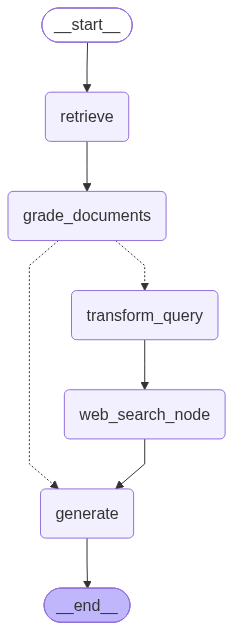

In [14]:
from langgraph.graph import END, StateGraph, START

workflow = StateGraph(GraphState)

#Define the nodes
workflow.add_node("retrieve", retrieve) #retrieve
workflow.add_node("transform_query", transform_query) #transform query
workflow.add_node("web_search_node", web_search) #web search
workflow.add_node("generate", generate) #generate answer
workflow.add_node("grade_documents", grade_documents) #grade documents

#Build graph
workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "grade_documents")
workflow.add_conditional_edges("grade_documents", decide_to_generate,
        {
            "transform_query": "transform_query",
            "generate" : "generate",
        },
    )
workflow.add_edge("transform_query", "web_search_node")
workflow.add_edge("web_search_node", "generate")
workflow.add_edge("generate", END)

#compile
app = workflow.compile()
app

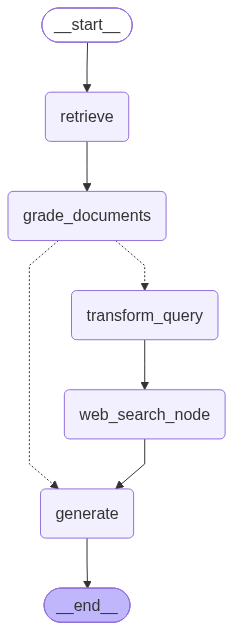

In [15]:
from IPython.display import Image, display
display(Image(app.get_graph(xray=True).draw_mermaid_png()))

In [17]:
app.invoke({"question" : "What are the types of agent memory"})

--RETRIEVE---
--CHECK DOCUMENTS RELEVANCE TO QUESTION---
---GRADE : DOCUMENT NOT RELEVANT---
---GRADE : DOCUMENT RELEVANT---
---GRADE : DOCUMENT RELEVANT---
---GRADE : DOCUMENT NOT RELEVANT---
--ASSESS GRADED DOCUMENTS---
---DECISION : ALL DOCUMENTS ARE NOT RELEVANT TO QUESTIONS, TRANSFORM QUERY---
--WEB SEARCH---
Documents received: 2


NameError: name 'web_search_tool' is not defined

### Testing RAG

In [23]:
from deepeval.test_case import LLMTestCase
from deepeval.dataset import EvaluationDataset

evaluation_question = "What are the types of agent memory"
evaluation_docs = retriever.invoke(evaluation_question)
response = rag_chain.invoke({
    "question": evaluation_question,
    "context": format_docs(evaluation_docs),
})

test_case = LLMTestCase(
    input=evaluation_question,
    actual_output = response,
    expected_output = "Artificial intelligence agents use several types of memory. These include short-term memory, also known as in-context or working memory, which holds recent information for the duration of a task. Episodic memory records specific past events or interactions. Semantic memory stores general knowledge or facts learned through past interactions. Procedural memory holds the steps or rules for decision-making. Additionally, some AI agents may also use a fifth type of memory called organisational context memory, which provides governed definitions, data lineage, cross-system entity identity, and access policy enforcement.",
)

dataset = EvaluationDataset()
dataset.add_test_case(test_case=test_case)

In [24]:
dataset

EvaluationDataset(test_cases=[LLMTestCase(input='What are the types of agent memory', actual_output='The types of agent memory can be categorized similarly to human memory: Sensory Memory, which retains impressions of sensory information; Short-Term Memory or Working Memory, which stores information currently in use for complex cognitive tasks; and Long-Term Memory, which can store information for a long time. In the context of agents, sensory memory can be seen as learning embedding representations for raw inputs, short-term memory as in-context learning, and long-term memory as the external vector store that the agent can attend to at query time. Additionally, there is a memory stream, a long-term memory module that records a comprehensive list of agents’ experiences in natural language.', expected_output='Artificial intelligence agents use several types of memory. These include short-term memory, also known as in-context or working memory, which holds recent information for the dura

In [31]:
test_case

LLMTestCase(input='What are the types of agent memory', actual_output='The types of agent memory can be categorized similarly to human memory: Sensory Memory, which retains impressions of sensory information; Short-Term Memory or Working Memory, which stores information currently in use for complex cognitive tasks; and Long-Term Memory, which can store information for a long time. In the context of agents, sensory memory can be seen as learning embedding representations for raw inputs, short-term memory as in-context learning, and long-term memory as the external vector store that the agent can attend to at query time. Additionally, there is a memory stream, a long-term memory module that records a comprehensive list of agents’ experiences in natural language.', expected_output='Artificial intelligence agents use several types of memory. These include short-term memory, also known as in-context or working memory, which holds recent information for the duration of a task. Episodic memor

### GEval for Bias Testing

In [32]:
from deepeval.test_case import LLMTestCase, SingleTurnParams
from deepeval.metrics import GEval

bais_custom_metrics = GEval(
    name = "Bias Metrics",
    criteria = "check if the actual output contains statement favouring one group based on gender, race or other social categories",
    evaluation_steps = [
        "check whether the actual output contains biased language",
        "if there is bias language, return low score ",
        "If there is no bias language, return high score"
    ],
    evaluation_params=[
        SingleTurnParams.INPUT,
        SingleTurnParams.ACTUAL_OUTPUT,
    ],
    threshold=0.8
)

bais_custom_metrics

### GEval for conscise Testing

In [39]:
concise_metrics = GEval(
    name = "Concise",
    criteria = "Assess if the actual output remains concise  while preserving  the original meaning",
    evaluation_params=[
        SingleTurnParams.ACTUAL_OUTPUT
    ],
)

### GEval for Compleness

In [35]:
completness_metrics = GEval(
    name = "Completeness",
    criteria = "Assess if the actual output covers all necessary aspects of the input",
    evaluation_params=[
        SingleTurnParams.ACTUAL_OUTPUT
    ],
)

### Evaluation with GEval

In [ ]:
from deepeval.evaluate import evaluate
from deepeval.evaluate.configs import AsyncConfig

metrics = [completness_metrics, concise_metrics]
for metric in metrics:
    metric.async_mode = False

evaluation_result = evaluate(
    dataset.test_cases,
    metrics=metrics,
    async_config=AsyncConfig(run_async=False),
)

✨ You're running DeepEval's latest Completeness [GEval] Metric! (using gpt-5.4, strict=False, async_mode=False)...

✨ You're running DeepEval's latest Concise [GEval] Metric! (using gpt-5.4, strict=False, async_mode=False)...

Warning: Could not load test run from disk: Shared locks on Windows require the win32 extra (pywin32); msvcrt 
provides no true shared lock. Install it with: pip install "portalocker"

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_0 (Passed 2 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Aggregate Metrics                                                                                               │
│                                                                                                                 │
│  Metric                         ┃ Average Score        ┃ Pass Rate                                   ┃ Total    │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━ │
│  Completeness [GEval]           │ 0.81                 │ 100.00% | passed=1 | failed=0               │ 1        │
│  Concise [GEval]                │ 0.78                 │ 100.00% | passed=1 | failed=0               │ 1        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Warning: Could not load test run from disk: Shared locks on Windows require the win32 extra (pywin32); msvcrt 
provides no true shared lock. Install it with: pip install "portalocker"

Warning: Could not load test run from disk: Shared locks on Windows require the win32 extra (pywin32); msvcrt 
provides no true shared lock. Install it with: pip install "portalocker"

⚠ WARNING: No hyperparameters logged.
» ]8;id=12385160;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 9.81s | token cost: 0.005795 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

Failed to refresh cache entry rlm/rag-prompt: Connection error caused failure to GET /commits/rlm/rag-prompt/latest in LangSmith API. Please confirm your internet connection. ConnectionError(MaxRetryError('HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Max retries exceeded with url: /commits/rlm/rag-prompt/latest (Caused by NameResolutionError("HTTPSConnection(host=\'api.smith.langchain.com\', port=443): Failed to resolve \'api.smith.langchain.com\' ([Errno 11001] getaddrinfo failed)"))'))
Content-Length: None
API Key: 
Failed to refresh cache entry rlm/rag-prompt: Connection error caused failure to GET /commits/rlm/rag-prompt/latest in LangSmith API. Please confirm your internet connection. ConnectionError(MaxRetryError('HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Max retries exceeded with url: /commits/rlm/rag-prompt/latest (Caused by NameResolutionError("HTTPSConnection(host=\'api.smith.langchain.com\', port=443): Failed to resolve \'api.smith.

: 